In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.utils import timeseries_dataset_from_array
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
import warnings



In [2]:
warnings.filterwarnings("ignore")
import kagglehub, glob
path = kagglehub.dataset_download("sudalairajkumar/daily-temperature-of-major-cities")
df = pd.read_csv(glob.glob(path + "/*.csv")[0])
print(df.shape)
df.head()

Using Colab cache for faster access to the 'daily-temperature-of-major-cities' dataset.
(2906327, 8)


,Region,Country,State,City,Month,Day,Year,AvgTemperature
0,Africa,Algeria,NaN,Algiers,1,1,1995,64.2
1,Africa,Algeria,NaN,Algiers,1,2,1995,49.4
2,Africa,Algeria,NaN,Algiers,1,3,1995,48.8
3,Africa,Algeria,NaN,Algiers,1,4,1995,46.4
4,Africa,Algeria,NaN,Algiers,1,5,1995,47.9


In [3]:
city_df = df[df["City"]=="Tokyo"].copy()
city_df = city_df[city_df["AvgTemperature"]!=-99]
city_df.reset_index(drop=True,inplace=True)
print(city_df.shape)
city_df.head()

(9237, 8)


,Region,Country,State,City,Month,Day,Year,AvgTemperature
0,Asia,Japan,NaN,Tokyo,1,1,1995,43.0
1,Asia,Japan,NaN,Tokyo,1,2,1995,40.8
2,Asia,Japan,NaN,Tokyo,1,3,1995,43.3
3,Asia,Japan,NaN,Tokyo,1,4,1995,44.9
4,Asia,Japan,NaN,Tokyo,1,5,1995,47.6


In [4]:
city_df = city_df[city_df["AvgTemperature"] != -99]
city_df.reset_index(drop=True, inplace=True)
print(city_df.shape)
city_df["Date"] = pd.to_datetime(city_df[["Year","Month","Day"]])
city_df = city_df.sort_values("Date")
city_df.reset_index(drop=True,inplace=True)
city_df.head()


(9237, 8)


,Region,Country,State,City,Month,Day,Year,AvgTemperature,Date
0,Asia,Japan,NaN,Tokyo,1,1,1995,43.0,1995-01-01
1,Asia,Japan,NaN,Tokyo,1,2,1995,40.8,1995-01-02
2,Asia,Japan,NaN,Tokyo,1,3,1995,43.3,1995-01-03
3,Asia,Japan,NaN,Tokyo,1,4,1995,44.9,1995-01-04
4,Asia,Japan,NaN,Tokyo,1,5,1995,47.6,1995-01-05


In [6]:
temperature = city_df[["AvgTemperature"]]
print(temperature.shape)
temperature.head()

(9237, 1)


,AvgTemperature
0,43.0
1,40.8
2,43.3
3,44.9
4,47.6


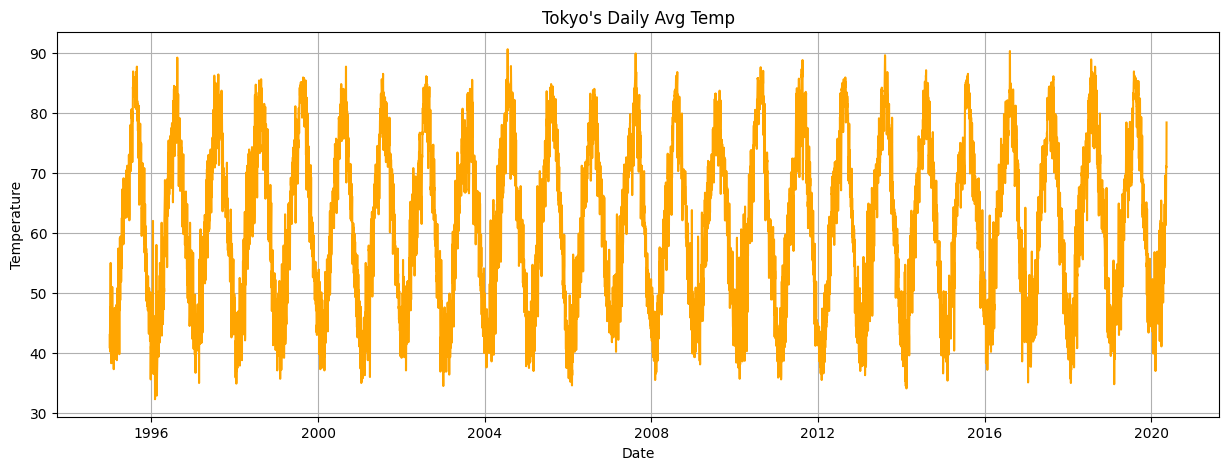

In [11]:
plt.figure(figsize=(15,5))
plt.plot(city_df["Date"],temperature,color="#FFA500")
plt.title("Tokyo's Daily Avg Temp")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.grid(True)
plt.show()


In [12]:
scaler = MinMaxScaler()
scaled_temperature = scaler.fit_transform(temperature)
print(scaled_temperature.shape)
train_size = int(len(scaled_temperature)*0.80)
train = scaled_temperature[:train_size]
test = scaled_temperature[train_size:]
print("Training Samples :",train.shape)
print("Testing Samples :",test.shape)


(9237, 1)
Training Samples : (7389, 1)
Testing Samples : (1848, 1)


In [13]:
from tensorflow.keras.utils import timeseries_dataset_from_array
lookback = 30
batch_size = 32
train_dataset = timeseries_dataset_from_array(
    data=train[:-lookback],
    targets=train[lookback:],
    sequence_length=lookback,
    sequence_stride=1,
    shuffle=False,
    batch_size=batch_size)
test_dataset = timeseries_dataset_from_array(
    data=test[:-lookback],
    targets=test[lookback:],
    sequence_length=lookback,
    sequence_stride=1,
    shuffle=False,
    batch_size=batch_size)
print("Training batches :", len(train_dataset))
print("Testing batches :", len(test_dataset))
for x, y in train_dataset.take(1):
    print("Input Shape :", x.shape)
    print("Output Shape :", y.shape)




Training batches : 230
Testing batches : 56
Input Shape : (32, 30, 1)
Output Shape : (32, 1)


In [14]:
from keras.utils import pad_sequences
sample_sequences = [[1,2,3],[4,5],[6,7,8,9]]
padded = pad_sequences(sample_sequences,maxlen=5,padding="pre")
print("Original Sequences")
print(sample_sequences)
print()


Original Sequences
[[1, 2, 3], [4, 5], [6, 7, 8, 9]]



In [15]:
print("Padded Sequences")
print(padded)

simple_rnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(lookback,1)),tf.keras.layers.SimpleRNN(64,activation="tanh"),
    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dense(1)])
simple_rnn.summary()




Padded Sequences
[[0 0 1 2 3]
 [0 0 0 4 5]
 [0 6 7 8 9]]


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
simple_rnn.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",patience=5,restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",factor=0.5,patience=3,verbose=1)
]
history_rnn = simple_rnn.fit(train_dataset,validation_data=test_dataset,epochs=10,callbacks=callbacks)



Epoch 1/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0125 - mae: 0.0815 - val_loss: 0.0047 - val_mae: 0.0547 - learning_rate: 0.0010
Epoch 2/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0049 - mae: 0.0551 - val_loss: 0.0041 - val_mae: 0.0490 - learning_rate: 0.0010
Epoch 3/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0043 - mae: 0.0515 - val_loss: 0.0042 - val_mae: 0.0493 - learning_rate: 0.0010
Epoch 4/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0042 - mae: 0.0503 - val_loss: 0.0041 - val_mae: 0.0484 - learning_rate: 0.0010
Epoch 5/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0040 - mae: 0.0489 - val_loss: 0.0039 - val_mae: 0.0472 - learning_rate: 0.0010
Epoch 6/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0040 - mae: 0.0487 - val_loss: 0.0039 - val_mae: 0.0482 - learning_rate: 0.0010
Epoch 7/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0041 - mae: 0.0495 - val_loss: 0.0040 - val_mae: 0.0479 - learning_rate: 0.0010

In [17]:
loss_rnn, mae_rnn = simple_rnn.evaluate(test_dataset,verbose=0)
print("SimpleRNN Loss :", loss_rnn)
print("SimpleRNN MAE :", mae_rnn)



SimpleRNN Loss : 0.003866021055728197
SimpleRNN MAE : 0.048181287944316864


In [18]:
stateful_rnn = tf.keras.Sequential([
    tf.keras.layers.Input(batch_shape=(1, lookback, 1)),
    tf.keras.layers.SimpleRNN(32,stateful=True),
    tf.keras.layers.Dense(1)
])
stateful_rnn.compile(
    optimizer="adam",loss="mse"
)
print("Stateful SimpleRNN Created Successfully")
stateful_rnn.summary()


Stateful SimpleRNN Created Successfully


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (1, 32)                │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (1, 1)                 │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
gru_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(lookback,1)),
    tf.keras.layers.GRU(64,activation="tanh"),
    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dense(1)
])
gru_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
history_gru = gru_model.fit(train_dataset,validation_data=test_dataset,epochs=10,callbacks=callbacks)


Epoch 1/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - loss: 0.0101 - mae: 0.0684 - val_loss: 0.0043 - val_mae: 0.0511 - learning_rate: 0.0010
Epoch 2/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - loss: 0.0043 - mae: 0.0511 - val_loss: 0.0041 - val_mae: 0.0502 - learning_rate: 0.0010
Epoch 3/10
228/230 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0044 - mae: 0.0515
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0042 - mae: 0.0505 - val_loss: 0.0040 - val_mae: 0.0492 - learning_rate: 0.0010
Epoch 4/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 0.0039 - mae: 0.0482 - val_loss: 0.0039 - val_mae: 0.0482 - learning_rate: 5.0000e-04
Epoch 5/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - loss: 0.0039 - mae: 0.0482 - val_loss: 0.0038 - val_mae: 0.0482 - learning_rate: 5.0000e-04
Epoch 6/10
228/230 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0040 - mae: 0.0491
Epoch 6: ReduceLROnPlateau reducing learning rat

In [21]:
loss_gru, mae_gru = gru_model.evaluate(test_dataset,verbose=0)
print("GRU Loss :", loss_gru)
print("GRU MAE :", mae_gru)


GRU Loss : 0.003787738038226962
GRU MAE : 0.04758881404995918


In [22]:
pred_rnn = simple_rnn.predict(test_dataset)
pred_gru = gru_model.predict(test_dataset)
actual = []
for _, y in test_dataset:
    actual.extend(y.numpy())
actual = np.array(actual)


56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


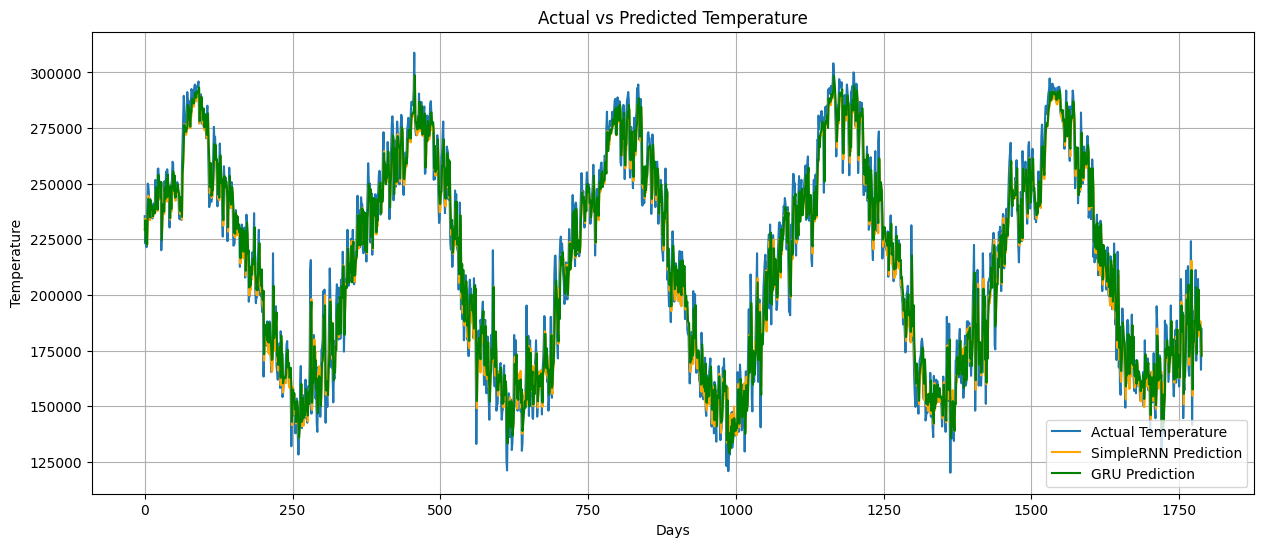

In [26]:
pred_rnn = scaler.inverse_transform(pred_rnn)
pred_gru = scaler.inverse_transform(pred_gru)
actual = scaler.inverse_transform(actual.reshape(-1,1))
plt.figure(figsize=(15,6))
plt.plot(actual,label="Actual Temperature")
plt.plot(pred_rnn,label="SimpleRNN Prediction",color="#FFA500")
plt.plot(pred_gru,label="GRU Prediction",color="g")
plt.title("Actual vs Predicted Temperature")
plt.xlabel("Days")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)
plt.show()


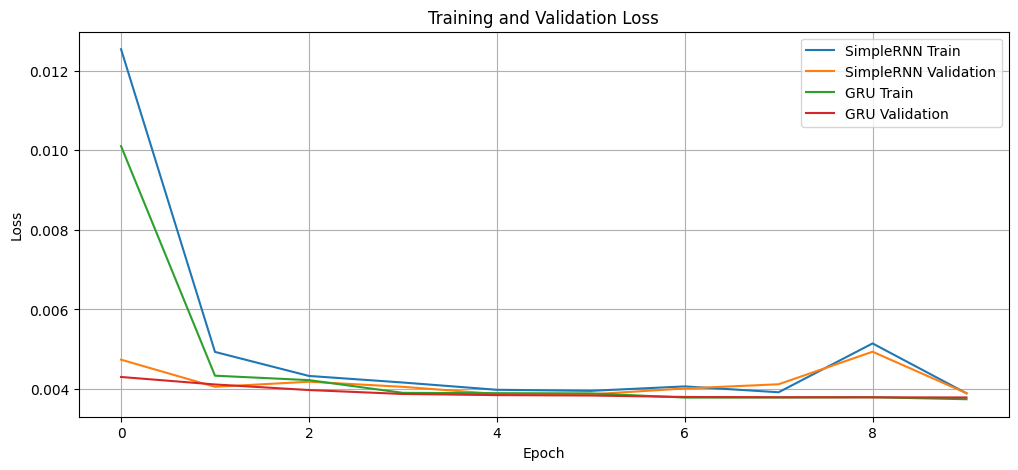

In [27]:
plt.figure(figsize=(12,5))
plt.plot(history_rnn.history["loss"],label="SimpleRNN Train")
plt.plot(history_rnn.history["val_loss"],label="SimpleRNN Validation")
plt.plot(history_gru.history["loss"],label="GRU Train")
plt.plot(history_gru.history["val_loss"],label="GRU Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [28]:
comparison = pd.DataFrame({
    "Model":["SimpleRNN","GRU"],
    "Loss":[loss_rnn,loss_gru],
    "MAE":[mae_rnn,mae_gru]
})
print(comparison)


       Model      Loss       MAE
0  SimpleRNN  0.003866  0.048181
1        GRU  0.003788  0.047589
